# Lab 11 (Week 3 — Lab 1): Neural Network Fundamentals

Welcome to Week 3 and Deep Learning! Before using any deep learning framework, this lab focuses on understanding exactly what a neural network computes — by implementing a neuron, a small forward pass, a loss calculation, and a gradient descent step yourself, using plain NumPy.

**For detailed theory — layers, activation functions, backpropagation — see the Lab 11 PDF and Learning Resources.**

**Note:** We are not training a real model with Keras in this lab — that starts in Lab 12 (Building Models with TensorFlow/Keras). Here, the goal is to understand the mechanics first.

**Instructions:**
- Write your code between the `### YOUR CODE HERE ###` and `### END ###` markers.
- Run each cell with **Shift + Enter**.
- Compare your output with the **Expected Output** shown below each exercise where provided.

## A Real Feature Vector to Work With

We'll use one real sample from the Wine dataset (built into scikit-learn, no download needed) so the numbers in this lab mean something real, even though we aren't training a model yet.

In [1]:
from sklearn.datasets import load_wine
import numpy as np

wine = load_wine()
X = wine.data
y = wine.target

print("Dataset shape:", X.shape)
first_sample = X[0]
print("First sample (13 features):", first_sample)
print("First sample's true class:", y[0])

Dataset shape: (178, 13)
First sample (13 features): [1.423e+01 1.710e+00 2.430e+00 1.560e+01 1.270e+02 2.800e+00 3.060e+00
 2.800e-01 2.290e+00 5.640e+00 1.040e+00 3.920e+00 1.065e+03]
First sample's true class: 0


## Example 1: A Single Neuron, Computed by Hand

In [2]:
def relu(z):
    return np.maximum(0, z)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# A single neuron with 3 made-up inputs (for simplicity, not the full 13-feature sample yet)
x = np.array([1.5, 2.0, 0.5])
w = np.array([0.4, -0.2, 0.9])
b = 0.1

z = np.dot(x, w) + b
output = relu(z)

print("Weighted sum (z):", z)
print("Neuron output (after ReLU):", output)

Weighted sum (z): 0.7500000000000001
Neuron output (after ReLU): 0.7500000000000001


## Example 2: Manual Forward Propagation (Two Layers)

In [3]:
X_toy = np.array([1.5, 2.0, 0.5])

W1 = np.array([[0.2, -0.5],
               [0.4,  0.1],
               [-0.3, 0.8]])
b1 = np.array([0.1, -0.2])

W2 = np.array([0.6, -0.9])
b2 = 0.05

hidden_z = np.dot(X_toy, W1) + b1
hidden_a = relu(hidden_z)

output_z = np.dot(hidden_a, W2) + b2
output = sigmoid(output_z)

print("Hidden layer activations:", hidden_a)
print("Final output (probability):", output)

Hidden layer activations: [1.05 0.  ]
Final output (probability): 0.6637386974043528


## Example 3: Calculating Loss

In [4]:
y_true = 1

mse = (y_true - output) ** 2
bce = -(y_true * np.log(output) + (1 - y_true) * np.log(1 - output))

print("Mean Squared Error:", mse)
print("Binary Cross-Entropy:", bce)

Mean Squared Error: 0.11307166362332144
Binary Cross-Entropy: 0.40986673496366205


## Example 4: One Gradient Descent Step, by Hand

In [5]:
w = 0.5
x_val, y_true_val = 2.0, 3.0
learning_rate = 0.1

prediction = w * x_val
loss = (prediction - y_true_val) ** 2

gradient = 2 * (prediction - y_true_val) * x_val
w_new = w - learning_rate * gradient

print("Prediction before update:", prediction)
print("Loss before update:", loss)
print("Gradient:", gradient)
print("Updated weight:", w_new)

Prediction before update: 1.0
Loss before update: 4.0
Gradient: -8.0
Updated weight: 1.3


## Practice Exercise 1: Try a Different Activation

**Exercise:** Repeat Example 1 (the single neuron), but use `sigmoid` instead of `relu` as the activation function. Print the new output.

In [6]:
output_sigmoid = None

### YOUR CODE HERE ###
output_sigmoid = sigmoid(z)
### END ###

print("Neuron output (sigmoid):", output_sigmoid)

Neuron output (sigmoid): 0.6791786991753931


## Practice Exercise 2: Forward Pass with a Real Wine Sample

**Exercise:** Using the `first_sample` from the Wine dataset (13 features), create a random weight vector `w_wine` of 13 values (use `np.random.randn(13)`) and a bias `b_wine = 0.1`. Compute the weighted sum and apply ReLU, just like Example 1.

In [7]:
np.random.seed(42)
w_wine = None
b_wine = 0.1
output_wine = None

### YOUR CODE HERE ###
w_wine = np.random.randn(13)

z_wine = np.dot(first_sample, w_wine) + b_wine
output_wine = relu(z_wine)
### END ###

print("Output for first wine sample:", output_wine)

Output for first wine sample: 264.2863167055308


## Practice Exercise 3: Multiple Gradient Descent Steps

**Exercise:** Repeat Example 4's gradient descent step 5 times in a row (using a loop), updating `w` each time. Print the weight and loss after each step. Does the loss get smaller each time?

In [8]:
w = 0.5
x_val, y_true_val = 2.0, 3.0
learning_rate = 0.1

### YOUR CODE HERE ###
for step in range(5):
    prediction = w * x_val

    gradient = 2 * (prediction - y_true_val) * x_val
    w = w - learning_rate * gradient

    prediction = w * x_val
    loss = (prediction - y_true_val) ** 2

    print(f"Step {step + 1}: weight = {w}, loss = {loss}")
### END ###

Step 1: weight = 1.3, loss = 0.15999999999999992
Step 2: weight = 1.46, loss = 0.006400000000000012
Step 3: weight = 1.492, loss = 0.0002560000000000005
Step 4: weight = 1.4984, loss = 1.0240000000000586e-05
Step 5: weight = 1.49968, loss = 4.0960000000025084e-07


_Write your observation about how the loss changes across the 5 steps here._

## Lab Tasks

Complete the following in this notebook, below this cell.

1. **Build a 3-Layer Forward Pass by Hand**: Using NumPy, manually compute a forward pass through a network with 2 hidden layers (your choice of size, e.g. 4 neurons then 3 neurons) and 1 output neuron, using any real wine sample as input. Use ReLU for hidden layers and sigmoid for the output.
2. **Try All Activation Functions**: For the same weighted sum `z`, compute and print the output using ReLU, Sigmoid, and Tanh (`np.tanh()`). Compare the three outputs in a markdown cell.
3. **Loss Comparison**: For 3 different made-up predictions (e.g., 0.9, 0.5, 0.1) against a true label of 1, compute both MSE and Binary Cross-Entropy for each. In a markdown cell, describe how the two loss functions behave differently as the prediction gets further from the true label.
4. **Gradient Descent Over Many Steps**: Extend Practice Exercise 3 to run 20 steps instead of 5. Plot the loss at each step using Matplotlib. Does it flatten out, and if so, around which step?
5. **Reflection**: In a markdown cell, write 3-4 sentences on how implementing these steps manually changed (or didn't change) your understanding of what a neural network actually does internally.

In [9]:
# Task 1

np.random.seed(42)

network_input = first_sample

W1_network = np.random.randn(13, 4) * 0.01
b1_network = np.array([0.1, 0.1, 0.1, 0.1])

W2_network = np.random.randn(4, 3) * 0.01
b2_network = np.array([0.1, 0.1, 0.1])

W3_network = np.random.randn(3) * 0.01
b3_network = 0.1

hidden1_z = np.dot(network_input, W1_network) + b1_network
hidden1_output = relu(hidden1_z)

hidden2_z = np.dot(hidden1_output, W2_network) + b2_network
hidden2_output = relu(hidden2_z)

final_z = np.dot(hidden2_output, W3_network) + b3_network
final_output = sigmoid(final_z)

print("First hidden layer:", hidden1_output)
print("Second hidden layer:", hidden2_output)
print("Final output:", final_output)

First hidden layer: [2.55014663 0.         2.1267785  0.        ]
Second hidden layer: [0.08978274 0.13634633 0.11610102]
Final output: 0.5256013632643548


I passed the 13 Wine measurements through hidden layers with four and three neurons, using ReLU after each one. The final neuron uses sigmoid to produce a value between zero and one. This demonstrates a forward pass with random weights; it does not predict the Wine dataset’s three classes.

In [10]:
# Task 2

print("Weighted sum:", z)
print("ReLU output:", relu(z))
print("Sigmoid output:", sigmoid(z))
print("Tanh output:", np.tanh(z))

Weighted sum: 0.7500000000000001
ReLU output: 0.7500000000000001
Sigmoid output: 0.6791786991753931
Tanh output: 0.6351489523872874


For the same weighted sum of approximately 0.75, ReLU returns 0.75, sigmoid returns about 0.679 and tanh returns about 0.635. ReLU leaves positive inputs unchanged. Sigmoid compresses values into the range zero to one, while tanh produces values between minus one and one.

In [11]:
# Task 3

y_true = 1

for prediction in [0.9, 0.5, 0.1]:
    mse = (y_true - prediction) ** 2

    bce = -(
        y_true * np.log(prediction)
        + (1 - y_true) * np.log(1 - prediction)
    )

    print(f"Prediction: {prediction}")
    print(f"MSE: {mse:.4f}")
    print(f"Binary Cross-Entropy: {bce:.4f}")
    print()

Prediction: 0.9
MSE: 0.0100
Binary Cross-Entropy: 0.1054

Prediction: 0.5
MSE: 0.2500
Binary Cross-Entropy: 0.6931

Prediction: 0.1
MSE: 0.8100
Binary Cross-Entropy: 2.3026



Both losses increase as the prediction moves further from the true label of 1. Binary cross-entropy increases particularly sharply when the model gives a low probability to the correct positive label. For this label, BCE becomes unbounded as the predicted probability approaches zero, while MSE approaches one.

Step 1: weight = 1.3, loss = 0.15999999999999992
Step 2: weight = 1.46, loss = 0.006400000000000012
Step 3: weight = 1.492, loss = 0.0002560000000000005
Step 4: weight = 1.4984, loss = 1.0240000000000586e-05
Step 5: weight = 1.49968, loss = 4.0960000000025084e-07
Step 6: weight = 1.499936, loss = 1.6384000000032773e-08
Step 7: weight = 1.4999872, loss = 6.553599999922159e-10
Step 8: weight = 1.49999744, loss = 2.6214399999688637e-11
Step 9: weight = 1.499999488, loss = 1.0485759998056466e-12
Step 10: weight = 1.4999998976, loss = 4.1943040028605647e-14
Step 11: weight = 1.49999997952, loss = 1.6777215865923107e-15
Step 12: weight = 1.499999995904, loss = 6.710886346369243e-17
Step 13: weight = 1.4999999991808, loss = 2.6843548295860084e-18
Step 14: weight = 1.49999999983616, loss = 1.0737425139111206e-19
Step 15: weight = 1.499999999967232, loss = 4.2949700556444824e-21
Step 16: weight = 1.4999999999934464, loss = 1.7180113054085245e-22
Step 17: weight = 1.4999999999986893, loss = 6.87

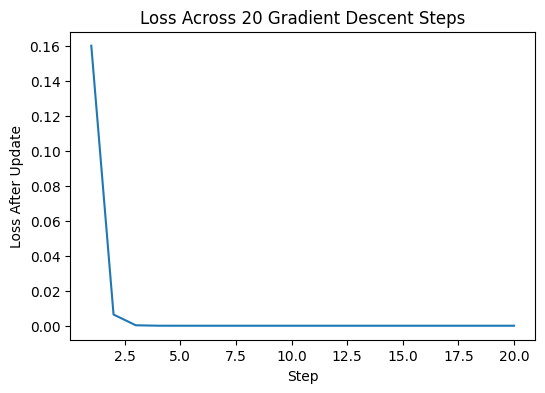

In [12]:
# Task 4

import matplotlib.pyplot as plt

w = 0.5
x_val, y_true_val = 2.0, 3.0
learning_rate = 0.1

losses = np.array([0.0] * 20)

for step in range(20):
    prediction = w * x_val

    gradient = 2 * (prediction - y_true_val) * x_val
    w = w - learning_rate * gradient

    prediction = w * x_val
    loss = (prediction - y_true_val) ** 2

    losses[step] = loss

    print(f"Step {step + 1}: weight = {w}, loss = {loss}")

plt.figure(figsize=(6, 4))
plt.plot(range(1, 21), losses)
plt.title("Loss Across 20 Gradient Descent Steps")
plt.xlabel("Step")
plt.ylabel("Loss After Update")
plt.show()

The loss falls quickly during the first few updates and looks almost flat by around steps 4–5 on this chart. It continues decreasing after that, but the remaining values are too small to see clearly on the plotted scale. The weight approaches 1.5.

_Write your Task 5 reflection here._

Working through the calculations helped me see how inputs, weights and biases produce a neuron’s output. I also understood how each layer passes its result to the next layer. Repeating gradient descent showed me how adjusting a weight can reduce the loss. This lab demonstrated the calculations separately, but I have not yet trained a complete neural network using backpropagation.